In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from numpy import log
from scipy.stats import ks_2samp, pareto, kstest, linregress, genpareto, expon, kstest, rv_continuous, kstest, ks_2samp
import statsmodels.api as sm
from scipy.optimize import minimize_scalar
from scipy.special import gamma, gammainc, gammaincc, zeta, erf
from Helpers import *
import pickle
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [2]:
df = pd.read_csv("data.csv")
F = df["Fatalities"].values
N = len(F)
x_min = np.min(F)

In [3]:
ic_df = pd.DataFrame(columns = ["Model","pmf", "params", "R", "AIC", "BIC"])
models = ["powerlaw", "lognorm", "expo", "weibull", "yule-simon"]
for model in models:
    fit = MLE(F, model, x_min)
    AIC = 2*len(fit[0]) - 2*fit[1]
    BIC = np.log(N)*len(fit[0]) - 2*fit[1]
    ic_df.loc[len(ic_df)] = [model, model, np.round(fit[0], 2), round(fit[1]), round(AIC), round(BIC)]
ic_df

,Model,pmf,params,R,AIC,BIC
0,powerlaw,powerlaw,[3.51],-564,1130,1134
1,lognorm,lognorm,"[-3.79, 1.47]",-568,1141,1148
2,expo,expo,[0.39],-622,1246,1249
3,weibull,weibull,"[0.5, 0.24]",-582,1168,1176
4,yule-simon,yule-simon,[4.14],-567,1136,1140


In [4]:
ave = np.mean(F)
std = np.std(F)
model = "powerlaw"
params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
print(ave, std**2)
print(100*CCDF(30, model, params))
print(100*(0.5-0.5*erf((30-ave)/(std*np.sqrt(2)))))
sample = np.random.normal(ave, std, 10000000)
100*len(sample[sample>30])/len(sample)

6.100313479623824 27.66391839702833
0.4856988578310184
0.0002760239374288709


0.00029

In [5]:
plt.rcParams.update({
    'font.size' : 18,
    "lines.linewidth": 2,
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
        })

In [6]:
model = "powerlaw"
params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
alphas = []
for i in range(1000):
    f_sample = np.random.choice(F, size=N, replace=True)
    if f_sample.min()>4: print(i)
    alphas.append(MLE(f_sample, model, x_min)[0][0])
alpha_upper = np.max(alphas)
alpha_lower = np.min(alphas)

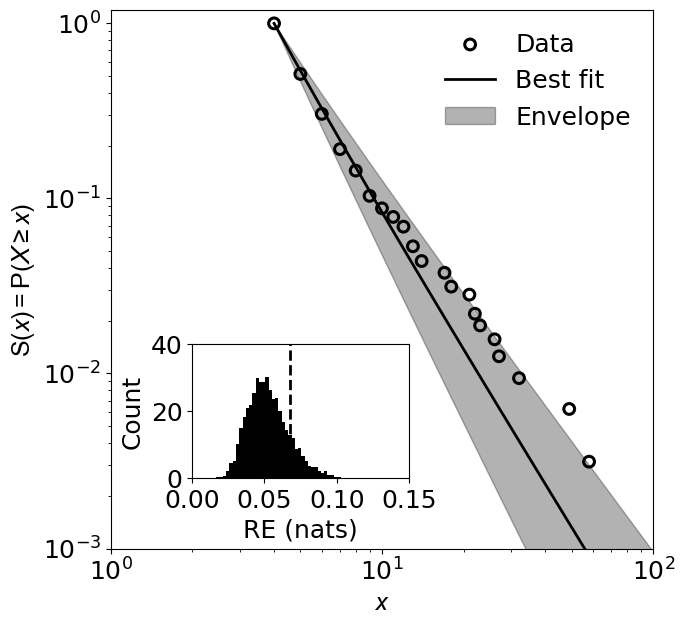

In [7]:
fig, axs = plt.subplots(1, 1, figsize=(7, 7))


Xs, Sx = plug_in_ccdf(F)
axs.scatter(Xs, Sx, facecolors='none', edgecolors='k', linewidths=2.2, s = 60, label = "Data")

axs.set_xlim([1, 100])
axs.set_ylim([1e-3, 1.2])
axs.set_xscale("log")
axs.set_yscale("log")
axs.set_ylabel(r"$\mathrm{S}(\it{x}) = \mathrm{P}(\it{X} \geq \it{x})$")
axs.set_xlabel(r"$\it{x}$")

model = "powerlaw"
Xs = np.arange(x_min, 100)
params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
params_p =  np.insert([alpha_upper], 0, x_min)
params_m =  np.insert([alpha_lower], 0, x_min)
fs = CCDF(Xs, model, params)
fs_p = CCDF(Xs, model, params_p)
fs_m = CCDF(Xs, model, params_m)

axs.plot(Xs, fs, color = "k", label = "Best fit")
axs.plot(Xs, fs_p, alpha = 0)
axs.plot(Xs, fs_m, alpha = 0)

axs.fill_between(
    Xs, fs_m, fs_p, 
    color="k", alpha=0.3, 
    label="Envelope"
)

axs.legend(frameon = False, loc = "upper right")


params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
X, Px = plug_in_pdf(F)
Real_RE = Relative_entropy(X, Px, model, params)

with open(f"Results/Surr_{model}.pkl", "rb") as f:
    RE = pickle.load(f)

# Define inset axes inside main plot
ax_inset = inset_axes(
    axs,
    width="40%",
    height="25%",
    loc="lower left",
    bbox_to_anchor=(0.15, 0.13, 1, 1),  # (x0, y0, width, height) relative to parent
    bbox_transform=axs.transAxes,
    borderpad=0,
)
ax_inset.hist(RE, bins=50, density=True, alpha=1, color="k", label="Surrogate")
ax_inset.axvline(Real_RE, color="k", lw=2, label="Real", linestyle="--")
ax_inset.set_ylim([0, 40])
ax_inset.set_xlim([0.0, 0.15])
ax_inset.set_xticks([0,0.05, 0.1,0.15])
ax_inset.set_ylabel("Count")
ax_inset.set_xlabel("RE (nats)")
# ax_inset.legend()
# plt.tight_layout()
plt.savefig("Figure.pdf", bbox_inches="tight")
plt.show()